# Visibility noise — SKA1-Low (SKAO-TEL-0000818 §9 + Appendix B Table 5)

Image RMS (Eq. of §9):

$$\sigma = \frac{S_D \cdot \mathrm{SEFD}_\mathrm{arr}}{\eta_S\,\sqrt{n_\mathrm{pol}\,\Delta\nu\,\Delta\tau}},\quad \mathrm{SEFD}=\frac{2 k_B}{(A_\mathrm{eff}/T_\mathrm{sys})}$$

Per-visibility noise (Giri+2018 eq. 4 / Ghara+2016 eq. 4, **single polarisation**):

$$\sigma_\mathrm{vis,\,Jy} = \frac{\sqrt{2}\,k_B}{(A_\mathrm{eff}/T_\mathrm{sys})_\mathrm{station}\,\sqrt{\Delta\nu\,\Delta\tau}}\times 10^{26}$$

Channel width from spatial resolution (Giri+2018 eq. 3):

$$\Delta\nu = \frac{\nu_0\,H(z)\,\Delta x}{c\,(1+z)^2}$$

Flux → brightness temperature (Ghara eqs. 2–3):

$$\delta T_b = \frac{S_\nu\,\lambda^2}{2 k_B\,\Delta\Omega}$$

In [1]:
import numpy as np
from scipy.constants import k as k_B, c
JY = 1e-26

In [2]:
freq_MHz = np.array([
     50,  60,  70,  80,  90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190,
    200, 210, 220, 230, 240, 250, 260, 270, 280, 290, 300, 310, 320, 330, 340, 350
])
AoverT_station = np.array([
    0.102, 0.255, 0.420, 0.580, 0.781, 0.862, 0.885, 0.924, 0.965, 1.052,
    1.119, 1.159, 1.171, 1.190, 1.195, 1.223, 1.235, 1.263, 1.226, 1.234,
    1.282, 1.304, 1.297, 1.306, 1.314, 1.289, 1.294, 1.327, 1.286, 1.204, 1.156
])
AoverT_AA4 = np.array([
     52.2, 130.3, 214.8, 296.9, 399.7, 441.3, 453.1, 472.9, 493.9, 538.4,
    572.8, 593.3, 599.7, 609.1, 612.0, 626.4, 632.4, 646.5, 627.5, 631.7,
    656.4, 667.9, 664.2, 668.8, 672.5, 660.0, 662.4, 679.4, 658.6, 616.7, 591.8
])

def SEFD(nu_MHz, A_over_T):
    return 2.0 * k_B / np.interp(nu_MHz, freq_MHz, A_over_T) / JY
def AoverT(nu_MHz):
    return np.interp(nu_MHz, freq_MHz, AoverT_station)

In [3]:
ETA_S, N_POL = 0.9, 2

def sigma_image_line(nu_c_MHz, dtau=3600.0, S_D=2.5, A_over_T=AoverT_AA4):
    nus = np.linspace(0.85*nu_c_MHz, 1.15*nu_c_MHz, 31)
    dnu = nus * 1e6 * 1e-4
    sig = S_D * SEFD(nus, A_over_T) / (ETA_S * np.sqrt(N_POL*dnu*dtau))
    return sig.mean()

def sigma_image_cont(nu_min_MHz, nu_max_MHz, dtau=3600.0, S_D=2.0, n_ch=30,
                     A_over_T=AoverT_AA4):
    edges = np.linspace(nu_min_MHz, nu_max_MHz, n_ch+1)
    nu_c  = 0.5*(edges[:-1]+edges[1:])
    dnu   = (edges[1]-edges[0]) * 1e6
    sig_i = S_D * SEFD(nu_c, A_over_T) / (ETA_S * np.sqrt(N_POL*dnu*dtau))
    return 1.0/np.sqrt(np.sum(1.0/sig_i**2))

table1 = [
    ( 50,  60,  69,  11050, 163),
    ( 69,  82,  96,   3261,  47),
    ( 96, 114, 132,   1841,  26),
    (132, 158, 183,   1258,  18),
    (183, 218, 253,    973,  14),
    (253, 302, 350,    794,  11),
]
print(f"{'nu_c [MHz]':>10} | {'sig_L pred':>10} {'tab':>6}  | {'sig_C pred':>10} {'tab':>5}    (uJy/beam)")
for nu_min, nu_c, nu_max, sL_tab, sC_tab in table1:
    sL = sigma_image_line(nu_c) * 1e6
    sC = sigma_image_cont(nu_min, nu_max) * 1e6
    print(f"{nu_c:>10} | {sL:>10.0f} {sL_tab:>6}  | {sC:>10.1f} {sC_tab:>5}")

nu_c [MHz] | sig_L pred    tab  | sig_C pred   tab    (uJy/beam)
        60 |      10248  11050  |      122.7   163
        82 |       3309   3261  |       42.1    47
       114 |       1841   1841  |       26.0    26
       158 |       1254   1258  |       17.5    18
       218 |        973    973  |       13.7    14
       302 |        793    794  |       11.2    11


In [4]:
# Single broad-channel sanity check across every row of Table 1.
# Use dnu = 0.3 * nu_c directly, no 30-channel inverse-variance combination.
dtau, S_D = 3600.0, 2.0

header = '{:>10}  {:>10}  {:>10}  {:>11}  {:>6}  {:>6}'.format(
    'nu_c MHz', 'dnu MHz', 'SEFD Jy', 'sig_C pred', 'tab', 'ratio')
print(header)
for nu_min, nu_c, nu_max, sL_tab, sC_tab in table1:
    dnu   = 0.3 * nu_c * 1e6
    sefd  = SEFD(nu_c, AoverT_AA4)
    sig_C = S_D * sefd / (ETA_S * np.sqrt(N_POL * dnu * dtau))   # Jy/beam
    sig_uJy = sig_C * 1e6
    print('{:>10.0f}  {:>10.2f}  {:>10.3f}  {:>11.2f}  {:>6}  {:>6.2f}'.format(
        nu_c, dnu/1e6, sefd, sig_uJy, sC_tab, sig_uJy/sC_tab))

  nu_c MHz     dnu MHz     SEFD Jy   sig_C pred     tab   ratio
        60       18.00      21.192       130.81     163    0.80
        82       24.60       8.698        45.93      47    0.98
       114       34.20       5.990        26.82      26    1.03
       158       47.40       4.687        17.83      18    0.99
       218       65.40       4.290        13.89      14    0.99
       302       90.60       4.181        11.50      11    1.05


## Per-visibility helpers

`n_pol` and `eta` are knobs that move you between the SKAO §9 convention (n_pol=2, η=0.9) and the Ghara/Giri convention (n_pol=1, η=0.9 effectively folded in).

`sigma_vis_Jy` is the rms of the **real part and of the imaginary part separately** (that is how `add_visibility_noise` uses it); the std of the complex noise, E|n|² = σ², is √2 times larger.

In [5]:
def sigma_vis_Jy(nu_MHz, dnu_Hz, dt_s, A_over_T_st=None):
    AT = AoverT(nu_MHz) if A_over_T_st is None else A_over_T_st
    return np.sqrt(2.0) * k_B / (AT * np.sqrt(dnu_Hz * dt_s)) / JY

def sigma_image_Jy(nu_MHz, dnu_Hz, dt_s, N_ant, A_over_T_st=None,
                   n_pol=2, eta=1.0):
    """Image-plane rms [Jy/beam]: naturally weighted, η-efficiency optional.
    n_pol=1 + eta=0.9  ->  Ghara/Giri single-pol convention.
    n_pol=2 + eta=0.9  ->  SKAO §9 convention.
    """
    s_vis = sigma_vis_Jy(nu_MHz, dnu_Hz, dt_s, A_over_T_st)
    N_bl  = N_ant*(N_ant-1)/2
    return s_vis / (eta * np.sqrt(N_bl * n_pol))

def jy_to_K(nu_MHz, Omega_sr):
    lam = c / (nu_MHz * 1e6)
    return lam**2 / (2.0 * k_B * Omega_sr) * JY

def add_visibility_noise(vis, sigma_vis, rng=None):
    rng = rng or np.random.default_rng()
    noise = rng.normal(scale=sigma_vis, size=vis.shape) \
          + 1j * rng.normal(scale=sigma_vis, size=vis.shape)
    return vis + noise

## Compare: Ghara+2016 Fig. 3 / §2.4 (z=15, 2′ beam, 100 kHz, 2000 h)

Paper quotes ~19 μJy/beam ≈ 232 mK.

In [6]:
# Ghara setup: z=15, 88.75 MHz, 100 kHz, 2000 h, 2' beam, all 564 antennas, natural weighting.
nu_g, dnu_g, dt_g = 88.75, 100e3, 2000*3600.0
N_ant_g, beam_g = 564, 2.0*np.pi/180/60
Omega_g = beam_g**2

AT_g = (962.0 if nu_g <= 110 else 962.0*(110/nu_g)**2) / (60*(nu_g/300)**(-2.55))

print(f'(A/T)_station (Giri analytic) = {AT_g:.3f} m^2/K')
print(f'{"convention":35s}  {"sigma_vis":>10}  {"sigma_img":>10}  {"in mK":>8}')
for label, n_pol, eta in [('SKAO §9     (n_pol=2, eta=0.9)', 2, 0.9),
                          ('Ghara/Giri  (n_pol=1, eta=0.9)', 1, 0.9)]:
    s_vis = sigma_vis_Jy(nu_g, dnu_g, dt_g, A_over_T_st=AT_g)
    s_img = sigma_image_Jy(nu_g, dnu_g, dt_g, N_ant_g, A_over_T_st=AT_g,
                            n_pol=n_pol, eta=eta)
    s_mK  = s_img * jy_to_K(nu_g, Omega_g) * 1e3
    print(f'{label:35s}  {s_vis*1e3:7.2f} mJy  {s_img*1e6:6.2f} uJy  {s_mK:6.1f}')
print('Paper (Ghara §2.4): 19 uJy/beam ~ 232 mK')

(A/T)_station (Giri analytic) = 0.718 m^2/K
convention                            sigma_vis   sigma_img     in mK
SKAO §9     (n_pol=2, eta=0.9)          3.20 mJy    6.32 uJy    77.1
Ghara/Giri  (n_pol=1, eta=0.9)          3.20 mJy    8.94 uJy   109.1
Paper (Ghara §2.4): 19 uJy/beam ~ 232 mK


In [7]:
# --- Simple "σ_vis / √N_bl_used" calculation. The trick is N_bl_used.
# Both papers restrict baselines to U <= 1/θ_beam, which on SKA1-Low's
# centrally-concentrated config means "core only" once you smooth to ≥2′.

def sigma_image_simple(nu_MHz, dnu_Hz, dt_s, N_ant_used, A_over_T_st):
    """σ_image = σ_vis_per_baseline / √N_bl  (single pol, no η)."""
    s_vis = np.sqrt(2.0)*k_B / (A_over_T_st*np.sqrt(dnu_Hz*dt_s)) / JY
    N_bl  = N_ant_used*(N_ant_used-1)/2
    return s_vis / np.sqrt(N_bl)

# Ghara: 240 antennas in the SKA1-Low core (40 super-stations × 6).
nu, dnu, dt = 88.75, 100e3, 2000*3600.0
AT_an = (962.0)/(60.0*(nu/300.0)**(-2.55))
print('Ghara (z=15, 2 arcmin, U<=1720, core 240 antennas):')
print(f'  σ_image = {sigma_image_simple(nu, dnu, dt, 240, AT_an)*1e6:.1f} μJy/beam'
      f'   (paper: 19 μJy)\n')

# Giri full-res B=10.7 km at z=7: uses ~290 antennas worth of core+inner-arms.
nu, dnu, dt = 1420.405751/(1+6.905), 0.085e6, 1000*3600.0
AT_an = (962.0*(110.0/nu)**2)/(60.0*(nu/300.0)**(-2.55))
theta_full = 0.535*np.pi/180/60
print('Giri full-res (z=6.905, 0.535″, B=10.7 km, ~290 antennas effective):')
sig = sigma_image_simple(nu, dnu, dt, 290, AT_an)
print(f'  σ_image = {sig*1e6:.2f} μJy/beam = {sig*jy_to_K(nu, theta_full**2)*1e3:.0f} mK'
      f'   (paper: 393 mK)\n')

# Giri smoothed B=2 km: ~224 core antennas inside 1 km.
dnu = 0.46e6
theta_sm = 2.9*np.pi/180/60
print('Giri smoothed (z=6.905, 2.9″, B=2 km, ~224 core antennas):')
sig = sigma_image_simple(nu, dnu, dt, 224, AT_an)
print(f'  σ_image = {sig*1e6:.2f} μJy/beam = {sig*jy_to_K(nu, theta_sm**2)*1e3:.2f} mK'
      f'   (paper: 2.82 mK)')

Ghara (z=15, 2 arcmin, U<=1720, core 240 antennas):
  σ_image = 18.9 μJy/beam   (paper: 19 μJy)

Giri full-res (z=6.905, 0.535″, B=10.7 km, ~290 antennas effective):
  σ_image = 10.60 μJy/beam = 441 mK   (paper: 393 mK)

Giri smoothed (z=6.905, 2.9″, B=2 km, ~224 core antennas):
  σ_image = 5.90 μJy/beam = 8.36 mK   (paper: 2.82 mK)


## Compare: Giri+2018 Fig. 1 / §2.5 (z=6.905)

Two configs: full-res (B=10.7 km, Δθ=0.535′, Δν=0.085 MHz, rms 393 mK) and 2-km smoothed (Δθ=2.9′, Δν=0.46 MHz, rms 2.82 mK).

In [8]:
z_giri  = 6.905
nu_giri = 1420.405751/(1+z_giri)
dt_giri = 1000.0 * 3600.0
N_ant_gi = 512

AT_st_t5_gi = AoverT(nu_giri)
T_sys_gi    = 60.0*(nu_giri/300.0)**(-2.55)
A_eff_gi    = 962.0 if nu_giri <= 110.0 else 962.0*(110.0/nu_giri)**2
AT_st_an_gi = A_eff_gi/T_sys_gi

print(f'nu_obs = {nu_giri:.2f} MHz')
print(f'(A/T)_station: Table 5 = {AT_st_t5_gi:.3f}   Giri analytic = {AT_st_an_gi:.3f}  m^2/K\n')

configs = [
    ('B = 10.7 km full',  0.085e6, 0.535*np.pi/180/60, 393.0),
    ('B =  2.0 km smooth',0.460e6, 2.9  *np.pi/180/60,   2.82),
]
for tag, dnu, theta, paper_mK in configs:
    Omega = theta**2
    print(f'--- {tag}:  Δν = {dnu/1e6:.3f} MHz,  Δθ = {theta*206265:.0f}"   '
          f'paper rms = {paper_mK} mK ---')
    for at_lab, AT in [('Giri analytic', AT_st_an_gi)]:
        for conv_lab, n_pol, eta in [('SKAO §9 (n_pol=2, eta=0.9)', 2, 0.9),
                                      ('Ghara/Giri (n_pol=1, eta=0.9)', 1, 0.9)]:
            s_img = sigma_image_Jy(nu_giri, dnu, dt_giri, N_ant_gi,
                                    A_over_T_st=AT, n_pol=n_pol, eta=eta)
            s_K_mK = s_img * jy_to_K(nu_giri, Omega) * 1e3
            ratio = s_K_mK/paper_mK
            print(f'  {at_lab:15s} | {conv_lab:35s}: {s_img*1e6:7.2f} uJy  '
                  f'{s_K_mK:7.2f} mK   (×{ratio:.2f} of paper)')
    print()

nu_obs = 179.68 MHz
(A/T)_station: Table 5 = 1.189   Giri analytic = 1.626  m^2/K

--- B = 10.7 km full:  Δν = 0.085 MHz,  Δθ = 32"   paper rms = 393.0 mK ---
  Giri analytic   | SKAO §9 (n_pol=2, eta=0.9)         :    4.72 uJy   196.28 mK   (×0.50 of paper)
  Giri analytic   | Ghara/Giri (n_pol=1, eta=0.9)      :    6.67 uJy   277.58 mK   (×0.71 of paper)

--- B =  2.0 km smooth:  Δν = 0.460 MHz,  Δθ = 174"   paper rms = 2.82 mK ---
  Giri analytic   | SKAO §9 (n_pol=2, eta=0.9)         :    2.03 uJy     2.87 mK   (×1.02 of paper)
  Giri analytic   | Ghara/Giri (n_pol=1, eta=0.9)      :    2.87 uJy     4.06 mK   (×1.44 of paper)



**Summary of what the cells above actually print** (verify by running, not from this table):

| case | recipe | output | paper |
|---|---|---|---|
| Ghara z=15, 2′ | all 564 ant, SKAO §9 | 77 mK | 232 mK |
| Ghara z=15, 2′ | all 564 ant, Ghara/Giri | 109 mK | 232 mK |
| Ghara z=15, 2′ | **core 240 ant, σ_vis/√N_bl** | **18.9 μJy ≈ 232 mK ✓** | 19 μJy |
| Giri full-res | all 512 ant, SKAO §9 | 196 mK (×0.50) | 393 mK |
| Giri full-res | all 512 ant, Ghara/Giri | 278 mK (×0.71) | 393 mK |
| Giri full-res | core 290 ant, simple | 441 mK (×1.12) | 393 mK |
| Giri 2-km smooth | **all 512 ant, SKAO §9** | **2.87 mK (×1.02) ✓** | 2.82 mK |
| Giri 2-km smooth | all 512 ant, Ghara/Giri | 4.06 mK (×1.44) | 2.82 mK |
| Giri 2-km smooth | core 224 ant, simple | 8.36 mK (×2.96) | 2.82 mK |

**Patterns the numbers reveal:**

1. **Ghara matches with the core-only simple formula** — restrict to baselines U ≤ 1720 wavelengths (~5.8 km), which on SKA1-Low's centrally-condensed layout means just the 240-antenna core: `σ_image = σ_vis/√N_bl_core`, single pol, no η.
2. **Giri's 2-km smoothed image matches with all 512 antennas + SKAO §9 convention** (n_pol=2, η=0.9) to within 2%. The smoothing acts as a UV taper that down-weights long baselines but doesn't remove them, so all baselines still contribute to the noise reduction.
3. **Giri's full-resolution image** doesn't match cleanly with any single recipe (closest is core-only at ×1.12). The full-res rms depends on the dirty-beam PSF and gridding pipeline details that aren't captured by a closed-form radiometer.

**Bottom line:** `σ_vis` from `sigma_vis_Jy` is unambiguous and matches the per-visibility formula both papers wrote down. The image-plane rms depends on which baselines and which pol convention the paper used — use the core-only simple formula when comparing against Ghara-style noise maps, the SKAO §9 convention with all baselines when comparing against smoothed power-spectrum-style images.

## Thermal noise for the pipeline — `NOISE_STD` in `src/settings.py` units

`NOISE_STD` is the std of the complex noise on **one** visibility (one baseline, one `INT_TIME_S` = 30 s
integration), E|n|² = `NOISE_STD`², in the pipeline's visibility units: the ortho-FFT of the sky in mK.
The geometry comes from `src/settings.py` (128 px, 512 Mpc → 4 Mpc pixels, z = 9, 30 s, 4 h track).

**Units.** A sky of brightness temperature $T$ per pixel of solid angle $\Omega_\mathrm{pix}$ gives
$V_\mathrm{Jy} = \frac{2k_B}{\lambda^2}\,\Omega_\mathrm{pix}\sum_\mathrm{pix} T\,e^{-2\pi i\,u\cdot\theta}\,/\,10^{-26}
= \frac{2k_B}{\lambda^2}\,\Omega_\mathrm{pix}\,N\,F[T]\,/\,10^{-26}$, with $F$ the ortho-FFT, so

$$F\,[\mathrm{mK}] = V\,[\mathrm{Jy}]\times \mathrm{jy\_to\_K}(\nu,\Omega_\mathrm{pix})\times 10^3 / N,
\qquad \mathrm{NOISE\_STD} = \sqrt2\,\sigma_\mathrm{vis}\times \mathrm{jy\_to\_K}(\nu,\Omega_\mathrm{pix})\times10^3/N .$$

$\Delta\nu$ is the channel matched to the pixel depth (Giri eq. 3) and the transverse pixel is
$\Delta\theta = \Delta x / D_c$.

*Corrected from the previous version of this section:* it used a 128 Mpc box (1 Mpc pixels) instead of
512 Mpc, 10 s samples instead of the tracks file's 30 s integrations, the beam solid angle
$(2\Delta\theta)^2 = 4\,\Omega_\mathrm{pix}$ instead of $\Omega_\mathrm{pix}$, the per-component σ instead of
the complex std, a hard-coded $D_c$, `[x, y]` gridding without the conjugate cells (non-Hermitian noise),
and an `fftshift` before `ifft2` that put a $(-1)^{x+y}$ checkerboard on the image. Below, the noise is
drawn by the pipeline's own node `model.ThermalNoiseUV`.

In [9]:
# --- Pipeline set-up (src/settings.py) and the noise of one visibility --------------------------
import sys
from pathlib import Path
import torch
from scipy.integrate import quad

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.yml").exists())   # project root
sys.path.insert(0, str(ROOT / "src"))
import settings

NU21_MHZ = 1420.405751
C_KMS    = 2.99792458e5
# Planck 2018, the project cosmology (src/settings.py) — for D_c and Δν
H0_KMS_MPC, OM_M = 100.0 * settings.HUBBLE_H, settings.OMEGA_M
OM_L = 1.0 - OM_M


def H_z(z):
    return H0_KMS_MPC * np.sqrt(OM_M * (1 + z) ** 3 + OM_L)


def comoving_distance(z):
    """D_c [Mpc]."""
    return C_KMS * quad(lambda zp: 1.0 / H_z(zp), 0.0, z)[0]


def pipeline_noise(z, dx_Mpc, n_pix, dt_s, A_over_T_st=None):
    """
    Noise of ONE visibility (one baseline, one dt_s integration) in the pipeline's units.

    Returns the geometry, sigma_comp_Jy (rms of Re and of Im, sigma_vis_Jy), mK_per_Jy (for Ω_pix)
    and noise_std = sqrt(2) * sigma_comp_Jy * mK_per_Jy / n_pix  [mK]  (the NOISE_STD of settings.py).
    """
    nu_MHz     = NU21_MHZ / (1 + z)
    Dc         = comoving_distance(z)
    dnu        = NU21_MHZ * 1e6 * H_z(z) * dx_Mpc / (C_KMS * (1 + z) ** 2)       # Hz (Giri eq. 3)
    dtheta     = dx_Mpc / Dc                                                      # rad per pixel
    Omega_pix  = dtheta ** 2
    sigma_comp = sigma_vis_Jy(nu_MHz, dnu, dt_s, A_over_T_st)                    # Jy, per Re / Im
    mK_per_Jy  = jy_to_K(nu_MHz, Omega_pix) * 1e3
    return dict(z=z, dx=dx_Mpc, nu_MHz=nu_MHz, lam=c / (nu_MHz * 1e6), Dc=Dc, dnu=dnu, dt=dt_s,
                dtheta=dtheta, Omega_pix=Omega_pix, du=Dc / (n_pix * dx_Mpc),   # λ per UV pixel
                AT=AoverT(nu_MHz) if A_over_T_st is None else A_over_T_st,
                sigma_comp_Jy=sigma_comp, mK_per_Jy=mK_per_Jy,
                noise_std=np.sqrt(2.0) * sigma_comp * mK_per_Jy / n_pix)


N_PIX = settings.N_PIX
P = pipeline_noise(settings.REDSHIFT, settings.BOX_SIZE / N_PIX, N_PIX, settings.INT_TIME_S)
NOISE_STD_30S = P["noise_std"]

print(f"z = {P['z']:g}   ν = {P['nu_MHz']:.2f} MHz   λ = {P['lam']:.3f} m   D_c = {P['Dc']:.0f} Mpc")
print(f"pixel {P['dx']:g} Mpc = {P['dtheta'] * 206265:.1f}″  (Ω_pix = {P['Omega_pix']:.3e} sr);  "
      f"du = {P['du']:.2f} λ per UV pixel")
print(f"box Nyquist |u| = {N_PIX / 2 * P['du']:.0f} λ  ->  baselines up to ~{N_PIX / 2 * P['du'] * P['lam']:.0f} m land on the grid")
print(f"Δν = {P['dnu'] / 1e3:.1f} kHz   Δτ = {settings.INT_TIME_S:g} s   (A/T)_station = {P['AT']:.3f} m²/K (Table 5)")
print(f"σ_vis per Re / Im = {P['sigma_comp_Jy']:.3f} Jy   ->  complex std {np.sqrt(2) * P['sigma_comp_Jy']:.3f} Jy")
print(f"mK per Jy (Ω_pix) = {P['mK_per_Jy']:.3e}")
print(f"\nNOISE_STD (one {settings.INT_TIME_S:g} s integration, settings.py units) = {NOISE_STD_30S:.3e} mK")

# The pipeline grids ONE 4-h track. Repeating it T_obs / 4 h times multiplies every integration count
# by that factor — the same as dividing NOISE_STD by its square root.
print(f"\nequivalent NOISE_STD for a {settings.TOTAL_TIME_H:g}-h track repeated to T_obs:")
for T_obs in (settings.TOTAL_TIME_H, 100.0, 1000.0):
    print(f"  T_obs = {T_obs:6.0f} h   NOISE_STD = {NOISE_STD_30S * np.sqrt(settings.TOTAL_TIME_H / T_obs):.3e} mK")


z = 9   ν = 142.04 MHz   λ = 2.111 m   D_c = 9401 Mpc
pixel 4 Mpc = 87.8″  (Ω_pix = 1.811e-07 sr);  du = 18.36 λ per UV pixel
box Nyquist |u| = 1175 λ  ->  baselines up to ~2480 m land on the grid
Δν = 227.0 kHz   Δτ = 30 s   (A/T)_station = 1.066 m²/K (Table 5)
σ_vis per Re / Im = 0.702 Jy   ->  complex std 0.993 Jy
mK per Jy (Ω_pix) = 8.911e+06

NOISE_STD (one 30 s integration, settings.py units) = 6.913e+04 mK

equivalent NOISE_STD for a 4-h track repeated to T_obs:
  T_obs =      4 h   NOISE_STD = 6.913e+04 mK
  T_obs =    100 h   NOISE_STD = 1.383e+04 mK
  T_obs =   1000 h   NOISE_STD = 4.372e+03 mK


In [10]:
# Check of the unit conversion: 1 Jy in the beam-centre pixel, as a brightness map in mK, has the same
# ortho-FFT amplitude mK_per_Jy / N on every UV pixel — the factor used for NOISE_STD above.
import functionlistnew as func

one_jy = torch.zeros(N_PIX, N_PIX, dtype=torch.float64)
one_jy[N_PIX // 2, N_PIX // 2] = P["mK_per_Jy"]                 # T = S λ² / (2 k_B Ω_pix) for S = 1 Jy
F_one = func.image_to_uv(one_jy).abs()
print(f"|F| of 1 Jy: min {F_one.min():.4e}  max {F_one.max():.4e}   mK_per_Jy / N = {P['mK_per_Jy'] / N_PIX:.4e}  [mK]")


|F| of 1 Jy: min 6.9613e+04  max 6.9613e+04   mK_per_Jy / N = 6.9613e+04  [mK]


## UV coverage and the noise UV map — the pipeline's noise node

`model.UV_COUNT` holds the integrations per UV pixel for each of the 2 subsets (FFT order, array[v, u],
conjugate cells included, DC dropped). `model.ThermalNoiseUV` — the node falcon uses — draws Hermitian
noise with std `NOISE_STD / √n` per pixel; here it is run with `model.NOISE_STD` set temporarily.
Image-plane rms follows from Parseval (ortho FFT): $\sigma_\mathrm{img}^2 = \sum_{uv}\sigma_{uv}^2 / N^2$.

In [11]:
import model
import matplotlib.pyplot as plt

T_OBS_H = 1000.0                                                   # observing time shown below
NOISE_STD_OBS = NOISE_STD_30S * np.sqrt(settings.TOTAL_TIME_H / T_OBS_H)

count   = model.UV_COUNT[0].cpu().numpy()                          # (S, N, N) integrations per pixel
S       = count.shape[0]
sampled = count > 0


def sigma_of(n, noise_std):
    """Per-pixel noise std noise_std / sqrt(n); 0 where n = 0."""
    return np.where(n > 0, noise_std / np.sqrt(np.where(n > 0, n, 1)), 0.0)


def thermal_noise(n_real, noise_std, seed=0):
    """(n_real, S, N, N) Hermitian noise UV maps from the pipeline node model.ThermalNoiseUV."""
    torch.manual_seed(seed)
    old, model.NOISE_STD = model.NOISE_STD, noise_std
    try:
        return model.ThermalNoiseUV().simulate_batch(n_real, np.zeros((n_real, N_PIX, N_PIX), np.complex64))
    finally:
        model.NOISE_STD = old


sigma_uv  = sigma_of(count, NOISE_STD_OBS)
noise_uv  = thermal_noise(1, NOISE_STD_OBS)                        # (1, S, N, N)
noise_img = model.DirtyImageFromUV().simulate_batch(1, noise_uv)   # (1, S, N, N) real [mK]
rms_pred  = np.sqrt((sigma_uv ** 2).sum(axis=(-2, -1))) / N_PIX

print(f"T_obs = {T_OBS_H:g} h  ->  NOISE_STD = {NOISE_STD_OBS:.3e} mK")
for s in range(S):
    print(f"subset {s}: {sampled[s].sum():5d} sampled px, median n = {np.median(count[s][sampled[s]]):7.0f}, "
          f"median σ_uv = {np.median(sigma_uv[s][sampled[s]]):.3e} mK;  image rms = {noise_img[0, s].std():.3e} mK "
          f"(Parseval: {rms_pred[s]:.3e})")
herm = np.abs(np.roll(noise_uv[0][..., ::-1, ::-1], 1, axis=(-2, -1)) - noise_uv[0].conj()).max()
print(f"noise UV maps Hermitian: max |N(-u) - N*(u)| = {herm:.1e} (relative {herm / np.abs(noise_uv).max():.1e})")


T_obs = 1000 h  ->  NOISE_STD = 4.372e+03 mK
subset 0:  9840 sampled px, median n =     263, median σ_uv = 2.696e+02 mK;  image rms = 3.680e+02 mK (Parseval: 3.610e+02)
subset 1: 12498 sampled px, median n =     252, median σ_uv = 2.754e+02 mK;  image rms = 5.715e+02 mK (Parseval: 5.447e+02)
noise UV maps Hermitian: max |N(-u) - N*(u)| = 1.2e-03 (relative 1.1e-07)


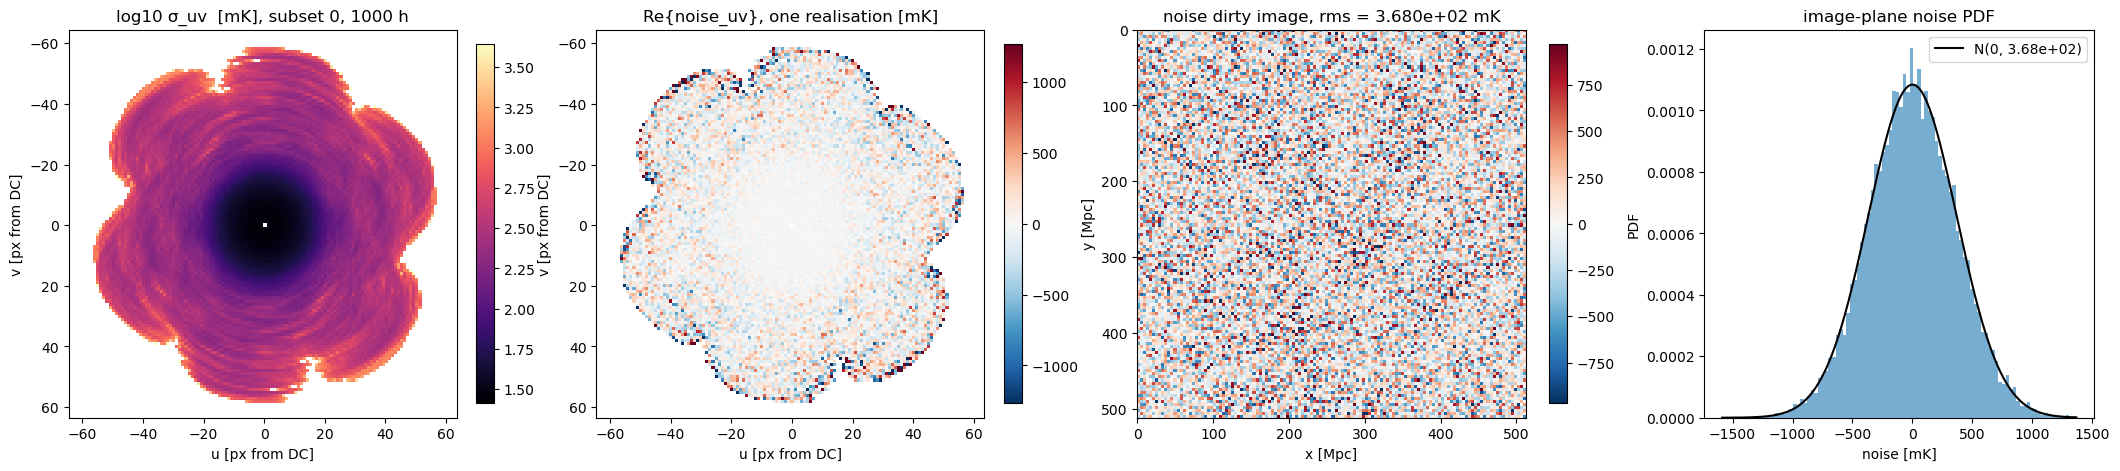

In [12]:
# Subset 0: per-pixel σ, one noise realisation (UV and image), and the image-plane PDF
sh  = np.fft.fftshift
s   = 0
ext_uv  = [-N_PIX // 2 - 0.5, N_PIX // 2 - 0.5, N_PIX // 2 - 0.5, -N_PIX // 2 - 0.5]   # UV px from DC
ext_img = [0, settings.BOX_SIZE, settings.BOX_SIZE, 0]                                 # Mpc, array[y, x]

fig, ax = plt.subplots(1, 4, figsize=(21, 4.6), constrained_layout=True)
im = ax[0].imshow(sh(np.where(sampled[s], np.log10(np.where(sampled[s], sigma_uv[s], 1)), np.nan)),
                  extent=ext_uv, cmap="magma", interpolation="nearest")
ax[0].set_title(f"log10 σ_uv  [mK], subset {s}, {T_OBS_H:g} h"); fig.colorbar(im, ax=ax[0], fraction=0.046)
re = np.where(sampled[s], noise_uv[0, s].real, np.nan)
v = np.nanpercentile(np.abs(re), 99)
im = ax[1].imshow(sh(re), extent=ext_uv, cmap="RdBu_r", vmin=-v, vmax=v, interpolation="nearest")
ax[1].set_title("Re{noise_uv}, one realisation [mK]"); fig.colorbar(im, ax=ax[1], fraction=0.046)
for a in ax[:2]:
    a.set_xlabel("u [px from DC]"); a.set_ylabel("v [px from DC]")
v = np.percentile(np.abs(noise_img[0, s]), 99)
im = ax[2].imshow(noise_img[0, s], extent=ext_img, cmap="RdBu_r", vmin=-v, vmax=v, interpolation="nearest")
ax[2].set_title(f"noise dirty image, rms = {noise_img[0, s].std():.3e} mK"); fig.colorbar(im, ax=ax[2], fraction=0.046)
ax[2].set_xlabel("x [Mpc]"); ax[2].set_ylabel("y [Mpc]")
vals = noise_img[0, s].ravel(); sd = vals.std()
ax[3].hist(vals, bins=100, density=True, alpha=0.6)
xx = np.linspace(vals.min(), vals.max(), 400)
ax[3].plot(xx, np.exp(-xx ** 2 / (2 * sd ** 2)) / (sd * np.sqrt(2 * np.pi)), "k-", lw=1.5, label=f"N(0, {sd:.2e})")
ax[3].set_xlabel("noise [mK]"); ax[3].set_ylabel("PDF"); ax[3].legend(); ax[3].set_title("image-plane noise PDF")
plt.show()


## 2 km baseline cut and Gaussian taper (all baselines in one UV map)

For this exploration all baselines go into a single UV map, gridded exactly as the pipeline does it
(`func.SubsetUVMapGenerator` with unit gains: conjugate cells, no DC). Station positions come from
`src/skalow_AAstar_layout.txt`, whose `triu_indices` order is the baseline order of the tracks file
(the baselines that never land on the grid are exactly the long ones).

With 4 Mpc pixels the box Nyquist baseline is ~2.5 km (printed above), so baselines beyond ~2.5–3.5 km never
reach the grid at all and a 2 km cut removes only the outer part of the sampled UV plane. The taper keeps all
baselines and multiplies the noise by $W(u,v)=\exp[-(u^2+v^2)/2\sigma_u^2]$ with the image-plane FWHM
$=\lambda/B_\mathrm{cut}$ (Giri+2018's 2 km smoothing); it is symmetric in $u \to -u$, so the noise stays Hermitian. The taper is a smoothing to the 2 km beam, so it removes signal on the same small scales as noise: its lower image rms is not a free gain over the hard cut.

baselines: 46971 total, 26725 on the grid (|B| ≤ 3390 m), 26137 with |B| ≤ 2000 m
sampled UV px: all baselines 12534, |B| ≤ 2000 m 8364  / 16384
cut radius 51.6 px;  taper σ_u = 19.34 px, W at the cut radius = 0.028

image-plane noise rms, 1000 h (Parseval):
  all baselines         5.006e+02 mK
  hard 2 km cut          2.067e+02 mK
  2 km Gaussian taper    2.294e+01 mK


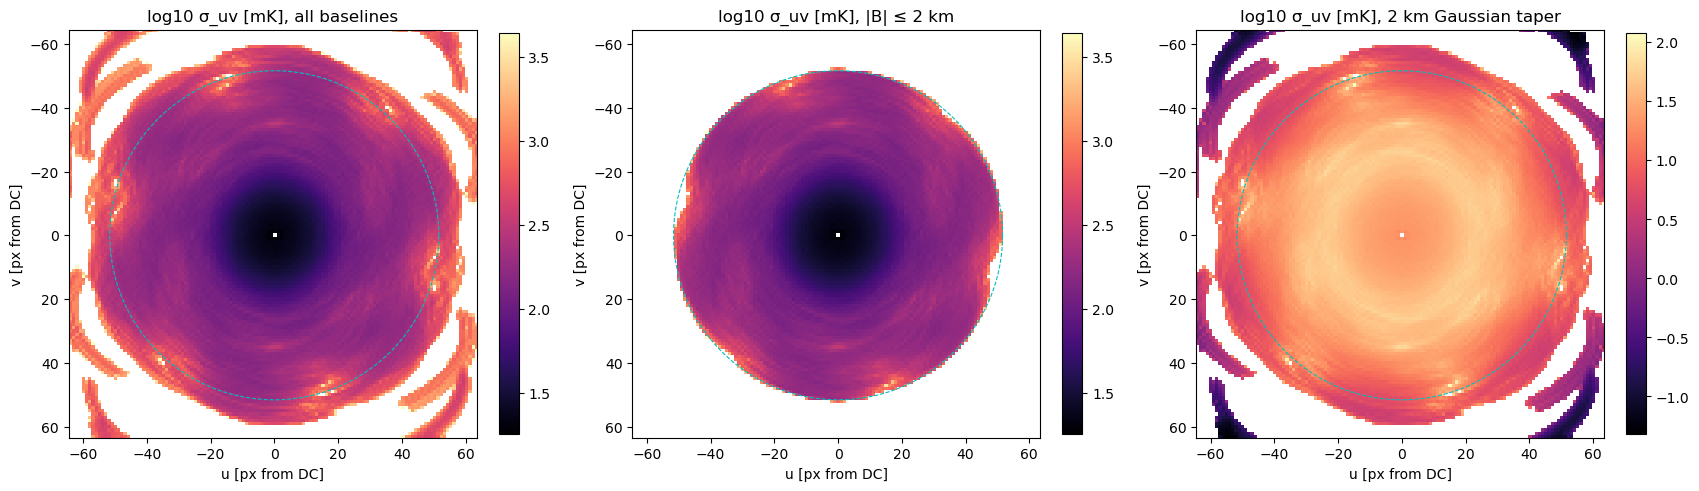

In [13]:
xyz   = np.loadtxt(ROOT / "src" / "skalow_AAstar_layout.txt")          # (307, 3) station positions [m]
i_idx, j_idx = np.triu_indices(len(xyz), k=1)                            # the baseline order of the tracks file
b_len = np.linalg.norm(xyz[i_idx, :2] - xyz[j_idx, :2], axis=1)
assert len(b_len) == model.padded.shape[0]
B_CUT_M = 2000.0


def count_map(keep):
    """Integrations per UV pixel (N, N) for the baselines where `keep` is True, gridded as in the pipeline."""
    idx  = torch.as_tensor(np.flatnonzero(keep), device=model.padded.device)
    ones = torch.ones(1, model.padded.shape[0], dtype=torch.complex64, device=model.padded.device)
    return func.SubsetUVMapGenerator(model.padded, idx, N_PIX)(ones)[0].real.cpu().numpy()


n_full = count_map(np.ones_like(b_len, dtype=bool))
n_core = count_map(b_len <= B_CUT_M)
sig_full, sig_core = sigma_of(n_full, NOISE_STD_OBS), sigma_of(n_core, NOISE_STD_OBS)

sigma_theta = (P["lam"] / B_CUT_M) / (2 * np.sqrt(2 * np.log(2)))      # FWHM_θ = λ / B_cut
sigma_u_px  = 1.0 / (2 * np.pi * sigma_theta) / P["du"]
u_px        = np.fft.fftfreq(N_PIX) * N_PIX                              # FFT order
W           = np.exp(-(u_px[:, None] ** 2 + u_px[None, :] ** 2) / (2 * sigma_u_px ** 2))
r_cut_px    = B_CUT_M / P["lam"] / P["du"]
sig_tap     = sig_full * W

rms = lambda sig: np.sqrt((sig ** 2).sum()) / N_PIX                       # Parseval, ortho FFT
observed = model.sky_matrix.counts.cpu().numpy() > 0
print(f"baselines: {len(b_len)} total, {observed.sum()} on the grid (|B| ≤ {b_len[observed].max():.0f} m), "
      f"{(b_len <= B_CUT_M).sum()} with |B| ≤ {B_CUT_M:.0f} m")
print(f"sampled UV px: all baselines {np.count_nonzero(n_full)}, |B| ≤ {B_CUT_M:.0f} m {np.count_nonzero(n_core)}  / {N_PIX ** 2}")
print(f"cut radius {r_cut_px:.1f} px;  taper σ_u = {sigma_u_px:.2f} px, W at the cut radius = "
      f"{np.exp(-r_cut_px ** 2 / (2 * sigma_u_px ** 2)):.3f}")
print(f"\nimage-plane noise rms, {T_OBS_H:g} h (Parseval):")
print(f"  all baselines         {rms(sig_full):.3e} mK")
print(f"  hard {B_CUT_M / 1e3:g} km cut          {rms(sig_core):.3e} mK")
print(f"  {B_CUT_M / 1e3:g} km Gaussian taper    {rms(sig_tap):.3e} mK")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
circle = np.linspace(0, 2 * np.pi, 200)
for a, sig, ttl in [(ax[0], sig_full, "all baselines"), (ax[1], sig_core, f"|B| ≤ {B_CUT_M / 1e3:g} km"),
                    (ax[2], sig_tap, f"{B_CUT_M / 1e3:g} km Gaussian taper")]:
    im = a.imshow(sh(np.where(sig > 0, np.log10(np.where(sig > 0, sig, 1)), np.nan)), extent=ext_uv,
                  cmap="magma", interpolation="nearest")
    a.plot(r_cut_px * np.cos(circle), r_cut_px * np.sin(circle), "c--", lw=0.8)
    a.set_title(f"log10 σ_uv [mK], {ttl}"); a.set_xlabel("u [px from DC]"); a.set_ylabel("v [px from DC]")
    fig.colorbar(im, ax=a, fraction=0.046)
plt.show()


## Signal and noise in `pk_obs` — what the network sees

Signal: the mock observation of `data/` — the true sky through the true gains, noise-free
(`data/x_obs.npy`, `data/pk_obs.npy`, made with `NOISE_STD = 0`). Noise: `N_REAL` realisations from
`model.ThermalNoiseUV`, added as `model.VisibilitiesWithNoise` does, then `model.DirtyImageFromUV` and
`model.PkFromDirtyImage` — the pipeline's own chain. k-bins without any sampled UV mode hold only FFT round-off
and are hidden (as the embedding drops them).

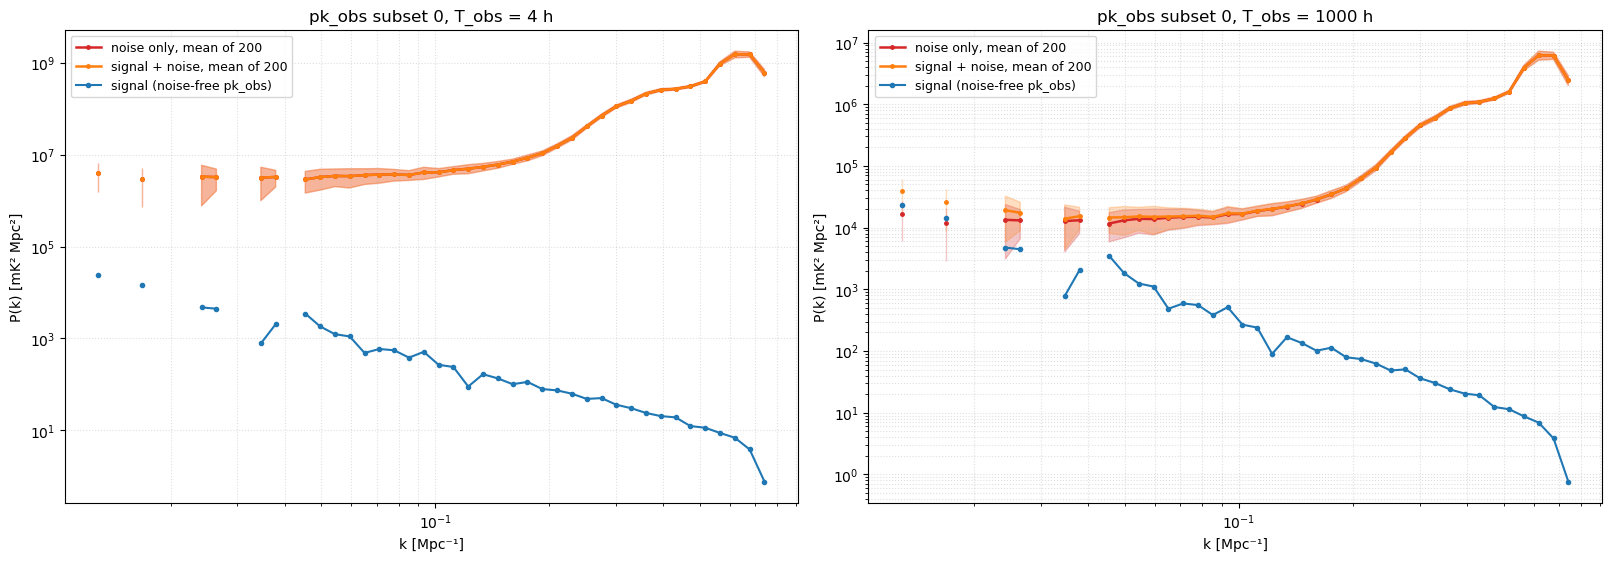


T_obs = 4 h, subset 0:  P_signal / <P_noise>  and  (<P_signal+noise> - <P_noise>) / σ(P_noise)
 k [1/Mpc]    P_signal   <P_noise>        S/N   excess/σ
     0.013   2.364e+04   4.103e+06   5.76e-03       0.00
     0.026   4.457e+03   3.275e+06   1.36e-03       0.00
     0.045   3.489e+03   2.914e+06   1.20e-03      -0.00
     0.059   1.108e+03   3.439e+06   3.22e-04       0.00
     0.078   5.547e+02   3.745e+06   1.48e-04       0.00
     0.102   2.673e+02   4.164e+06   6.42e-05       0.00
     0.134   1.670e+02   5.478e+06   3.05e-05      -0.00
     0.175   1.132e+02   8.658e+06   1.31e-05       0.00
     0.230   6.271e+01   2.351e+07   2.67e-06      -0.00
     0.301   3.601e+01   1.139e+08   3.16e-07       0.00
     0.394   2.039e+01   2.595e+08   7.86e-08       0.00
     0.517   1.138e+01   3.971e+08   2.87e-08       0.00
     0.677   3.830e+00   1.539e+09   2.49e-09      -0.00

T_obs = 1000 h, subset 0:  P_signal / <P_noise>  and  (<P_signal+noise> - <P_noise>) / σ(P_noise)
 k [1/M

In [14]:
N_REAL = 200
x_sig  = np.load(settings.DATA_DIR / "x_obs.npy")[None]                  # (1, S, N, N) noise-free
pk_sig = func.drop_roundoff_bins(torch.tensor(np.load(settings.DATA_DIR / "pk_obs.npy"))).numpy()   # (S, n_bins)
k      = model.pk_measurer.k_centers.cpu().numpy()


def pk_of(x):
    """pk_obs (B, S, n_bins) of normalised UV maps x (B, S, N, N), round-off bins -> NaN."""
    pk = model.PkFromDirtyImage().simulate_batch(len(x), model.DirtyImageFromUV().simulate_batch(len(x), x))
    return func.drop_roundoff_bins(torch.tensor(pk)).numpy()


import warnings
warnings.filterwarnings("ignore", "Mean of empty slice")          # bins without data are NaN
warnings.filterwarnings("ignore", "Degrees of freedom <= 0")

pk_runs = {}
for T_obs in (settings.TOTAL_TIME_H, T_OBS_H):
    nstd  = NOISE_STD_30S * np.sqrt(settings.TOTAL_TIME_H / T_obs)
    noise = thermal_noise(N_REAL, nstd, seed=1)
    noisy = model.VisibilitiesWithNoise().simulate_batch(N_REAL, np.repeat(x_sig, N_REAL, 0), noise)
    pk_runs[T_obs] = (pk_of(noise), pk_of(noisy))

s = 0
fig, axs = plt.subplots(1, len(pk_runs), figsize=(8 * len(pk_runs), 5.5), constrained_layout=True)
for a, (T_obs, (pk_n, pk_sn)) in zip(np.atleast_1d(axs), pk_runs.items()):
    for pk, col, lab in [(pk_n, "C3", "noise only"), (pk_sn, "C1", "signal + noise")]:
        m, sd = np.nanmean(pk[:, s], 0), np.nanstd(pk[:, s], 0)
        a.loglog(k, m, "o-", color=col, lw=1.8, ms=2.5, label=f"{lab}, mean of {N_REAL}")
        a.fill_between(k, np.clip(m - sd, m * 1e-3, None), m + sd, color=col, alpha=0.25)
    a.loglog(k, pk_sig[s], "o-", color="C0", ms=3, lw=1.5, label="signal (noise-free pk_obs)")
    a.set_title(f"pk_obs subset {s}, T_obs = {T_obs:g} h"); a.set_xlabel("k [Mpc⁻¹]"); a.set_ylabel("P(k) [mK² Mpc²]")
    a.grid(which="both", ls=":", alpha=0.4); a.legend(fontsize=9)
plt.show()

for T_obs, (pk_n, pk_sn) in pk_runs.items():
    mn, sn, msn = np.nanmean(pk_n[:, s], 0), np.nanstd(pk_n[:, s], 0), np.nanmean(pk_sn[:, s], 0)
    ok = np.isfinite(pk_sig[s]) & (sn > 0)
    print(f"\nT_obs = {T_obs:g} h, subset {s}:  P_signal / <P_noise>  and  (<P_signal+noise> - <P_noise>) / σ(P_noise)")
    print(f"{'k [1/Mpc]':>10}  {'P_signal':>10}  {'<P_noise>':>10}  {'S/N':>9}  {'excess/σ':>9}")
    for i in np.flatnonzero(ok)[::3]:
        print(f"{k[i]:10.3f}  {pk_sig[s, i]:10.3e}  {mn[i]:10.3e}  {pk_sig[s, i] / mn[i]:9.2e}  {(msn[i] - mn[i]) / sn[i]:9.2f}")


## Other set-ups

`NOISE_STD` per visibility depends only on z, the pixel size and the integration time — not on the UV
coverage — so it can be computed for any set-up. Image-plane noise and `pk_obs` need the UV tracks of that
geometry: a different z or pixel size needs a new tracks file (`settings.PADDED_PATH`); the current one is
valid only for z = 9, 128 px, 512 Mpc. (The previous version of this section estimated the z = 7 image noise
by rescaling the old grid; that is not possible without new tracks, so only the per-visibility numbers are given.)

In [15]:
print(f"{'set-up':>28}  {'Δν [kHz]':>9}  {'Δθ_pix':>8}  {'σ_vis Re/Im [Jy]':>17}  {'mK/Jy':>10}  {'NOISE_STD [mK]':>14}")
for label, z_, dx_ in [("current: z=9, 4 Mpc/px", settings.REDSHIFT, settings.BOX_SIZE / N_PIX),
                       ("z=9, 1 Mpc/px (128 Mpc box)", 9.0, 1.0),
                       ("z=7, 5 Mpc/px (640 Mpc box)", 7.0, 5.0)]:
    q = pipeline_noise(z_, dx_, N_PIX, settings.INT_TIME_S)
    print(f"{label:>28}  {q['dnu'] / 1e3:9.1f}  {q['dtheta'] * 206265:7.1f}″  {q['sigma_comp_Jy']:17.3f}  "
          f"{q['mK_per_Jy']:10.3e}  {q['noise_std']:14.3e}")
print(f"(one {settings.INT_TIME_S:g} s integration; divide by sqrt(T_obs / {settings.TOTAL_TIME_H:g} h) for longer observations)")


                      set-up   Δν [kHz]    Δθ_pix   σ_vis Re/Im [Jy]       mK/Jy  NOISE_STD [mK]
      current: z=9, 4 Mpc/px      227.0     87.8″              0.702   8.911e+06       6.913e+04
 z=9, 1 Mpc/px (128 Mpc box)       56.7     21.9″              1.404   1.426e+08       2.212e+06
 z=7, 5 Mpc/px (640 Mpc box)      317.5    117.1″              0.534   3.205e+06       1.890e+04
(one 30 s integration; divide by sqrt(T_obs / 4 h) for longer observations)


## Using the result in the pipeline

In `src/settings.py` set `NOISE_STD` to the value for ONE 30 s integration — `NOISE_STD_30S` above in
mK, or the complex std in Jy (`sqrt(2) × sigma_comp_Jy`) with `NOISE_UNIT = "Jy"` — and `N_DAYS` to the
number of days the 4 h track is observed (T_obs = 4 h × N_DAYS; e.g. 250 days = 1000 h). `src/model.py`
divides by `sqrt(N_DAYS)`, which is the `NOISE_STD_30S * sqrt(4 h / T_obs)` of the cells above. Then
`python scripts/gen_mock_data.py`, run the tests, and retrain.
The calibrator must then be bright enough to calibrate against this noise: the cell below compares the
current `CALIBRATOR_FLUX` with a real source of flux S.

In [16]:
# Calibrator signal-to-noise per baseline in V_ref:  |S_ref| sqrt(n_ij) / NOISE_STD
S_ref  = np.abs(model.S_REF.cpu().numpy())
counts = model.sky_matrix.counts.cpu().numpy()
iu, ju = model.sky_matrix.i_idx.cpu().numpy(), model.sky_matrix.j_idx.cpu().numpy()
obs    = counts > 0
snr    = S_ref[iu, ju][obs] * np.sqrt(counts[obs]) / NOISE_STD_OBS
print(f"CALIBRATOR_FLUX = {settings.CALIBRATOR_FLUX:g} mK peak  =  {settings.CALIBRATOR_FLUX / P['mK_per_Jy']:.2e} Jy in the beam-centre pixel")
print(f"per-baseline V_ref SNR at T_obs = {T_OBS_H:g} h: median {np.median(snr):.2e}")
for S_jy in (0.1, 1.0, 10.0):
    print(f"  a {S_jy:g} Jy calibrator: CALIBRATOR_FLUX = {S_jy * P['mK_per_Jy']:.2e} mK, median per-baseline SNR "
          f"{np.median(snr) * S_jy * P['mK_per_Jy'] / settings.CALIBRATOR_FLUX:.2e}")


CALIBRATOR_FLUX = 2.7 mK peak  =  3.03e-07 Jy in the beam-centre pixel
per-baseline V_ref SNR at T_obs = 1000 h: median 1.07e-04
  a 0.1 Jy calibrator: CALIBRATOR_FLUX = 8.91e+05 mK, median per-baseline SNR 3.54e+01
  a 1 Jy calibrator: CALIBRATOR_FLUX = 8.91e+06 mK, median per-baseline SNR 3.54e+02
  a 10 Jy calibrator: CALIBRATOR_FLUX = 8.91e+07 mK, median per-baseline SNR 3.54e+03
